# Болгарский мини-бенчмарк: MonoLM и Qwen

Сравнение **MonoLM-346M, шаг 5000** и **Qwen3-0.6B-Base** на 60 продолжениях и 20 вопросах в двух формулировках. Модели базовые, без чат-шаблонов. Этот ноутбук читает сохранённые результаты, **не запускает обучение или инференс**.

Входы, параметры и мягкая рубрика зафиксированы до генераций; неудачные ответы не перегенерировались. Основные показатели: минимальная пригодность продолжения, правильность ответа по контексту и правильность в обеих формулировках. Это три разных свойства, общего рейтинга из них не делаем.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image
from src.paths import ARTIFACTS
A = ARTIFACTS / "evaluation/bg-mini-v1"
read = lambda name: json.loads((A / name).read_text())
manifest = read("manifest.json")
report = read("report/summary.json")
assert report["complete"] and report["counts"]["generations"] == 200
display(pd.Series(report["counts"], name="Количество").to_frame())
print(f"GPU: {report['gpu_budget']['used_seconds']:.1f} / 1800 секунд")

,Количество
items,100
generations,200
primary_ratings,200
second_ratings,40
control_ratings,18


GPU: 637.1 / 1800 секунд


## Задания и воспроизводимость

Продолжения — первые подходящие документы в перемешанном seed 42 порядке validation; входы проверены до генерации. Начало заканчивается на границе предложения между 40-м и 80-м словом, иначе после 60-го. У каждого источника не менее 120 слов. Test не используется.

QA — [Belebele](https://huggingface.co/datasets/facebook/belebele), **упрощённая адаптация**, не официальный результат датасета. Выбраны 20 разных отрывков с явно указанным ответом; сохранены исходный вопрос, переформулировка, эталон и дословное подтверждение. Две демонстрации одинаковы для обеих моделей. Эталон не дописывается в слот ответа; сам контекст, естественно, содержит нужный факт.

Продолжения: температура 0,8, top-p 0,95, top-k отключён, максимум 80 слов / 256 новых токенов. QA: greedy, максимум 64 токена; судится первая непустая строка, полный вывод сохранён. Общий предел контекста 2048. Веса, входы и конфигурация имеют SHA-256 в manifest.

In [2]:
print("Qwen revision:", manifest["models"]["qwen"]["revision"])
print("Belebele revision:", manifest["dataset"]["revision"])
print("MonoLM export:", {k: manifest["models"]["monolm"][k] for k in ["step", "cpu_logits_exact", "tied_weights", "tokenizer_roundtrip"]})
lengths = read("prompt_lengths.json")
display(pd.DataFrame([{ "model": m, "min_prompt_tokens": min(v.values()), "max_prompt_tokens": max(v.values())} for m, v in lengths.items()]))

Qwen revision: da87bfb608c14b7cf20ba1ce41287e8de496c0cd
Belebele revision: dd9520af047cac89fd3b7f5d463f17144b1627a2
MonoLM export: {'step': 5000, 'cpu_logits_exact': True, 'tied_weights': True, 'tokenizer_roundtrip': True}


,model,min_prompt_tokens,max_prompt_tokens
0,monolm,50,254
1,qwen,91,493


## Рубрика и качество оценивания

Для продолжений судьи отдельно оценивают болгарский язык, понятность, связность и сохранение темы. Грамматические ошибки и простой стиль допустимы. Оценка связности 1 требует хотя бы двух связанных осмысленных фраз без преобладающей бессмыслицы. Внутренние противоречия учитываются; энциклопедическая достоверность не проверяется.

Минимальная пригодность: болгарский, все три оценки ≥1, нет преобладающего мусора/зацикливания и неопределённости. Отдельно показывается более высокий порог — все оценки 2. QA: полностью / частично / неправильно / неясно; строгая доля правильных включает только полностью правильные ответы.

Три подагента получали смешанные пакеты без названий моделей. 40 ответов оценены дважды, расхождения разобраны до раскрытия принадлежности. Каждый судья получил 6 контрольных примеров; контроли исключены из метрик. Это модельные оценки, не оценки носителей языка; один тип оценщика не даёт независимой человеческой проверки.

In [3]:
display(pd.DataFrame(report["controls"]))
display(pd.DataFrame(report["agreement"]).T)
print("Разобрано расхождений:", report["adjudications"])
print("Все контрольные примеры пройдены:", report["controls_passed"])

,judge,correct,total
0,1,6,6
1,2,6,6
2,3,6,6


,n,agreement,kappa,exact_rubric_agreement
continuation,24.0,0.958333,0.882353,0.666667
qa,16.0,1.000000,1.000000,1.000000


Разобрано расхождений: 8
Все контрольные примеры пройдены: True


## Результаты

95% интервалы получены парным bootstrap с 2000 повторами. Для продолжений единица — документ, для QA — исходный вопрос с двумя формулировками. Перефразировки не считаются независимыми вопросами. Разность всегда **MonoLM − Qwen**.

При отсутствии успехов bootstrap даёт вырожденный интервал [0; 0]. Он отражает только пересэмплирование имеющейся выборки и **не означает**, что истинная вероятность успеха точно равна нулю.

,block,metric,model,units,answers,value,ci_low,ci_high
0,continuation,minimal_acceptability,monolm,60,60,33.33,21.67,45.0
1,continuation,minimal_acceptability,qwen,60,60,11.67,5.00,20.0
2,continuation,all_scores_2,monolm,60,60,0.00,0.00,0.0
3,continuation,all_scores_2,qwen,60,60,0.00,0.00,0.0
4,qa,correct,monolm,20,40,0.00,0.00,0.0
5,qa,correct,qwen,20,40,47.50,27.50,67.5
6,qa,both_paraphrases_correct,monolm,20,40,0.00,0.00,0.0
7,qa,both_paraphrases_correct,qwen,20,40,40.00,20.00,60.0


,block,metric,comparison,value,ci_low,ci_high
0,continuation,minimal_acceptability,monolm_minus_qwen,21.67,6.62,36.67
1,continuation,all_scores_2,monolm_minus_qwen,0.00,0.00,0.00
2,qa,correct,monolm_minus_qwen,-47.50,-67.50,-27.50
3,qa,both_paraphrases_correct,monolm_minus_qwen,-40.00,-60.00,-20.00


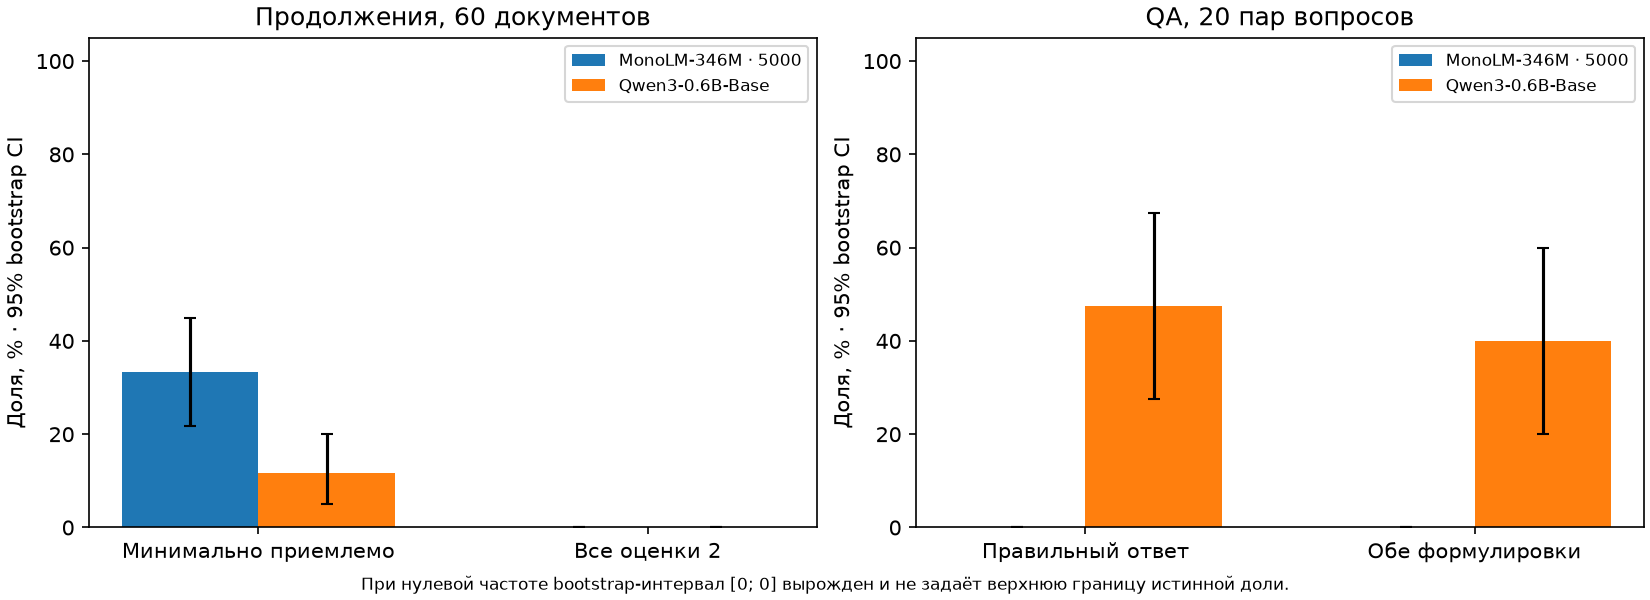

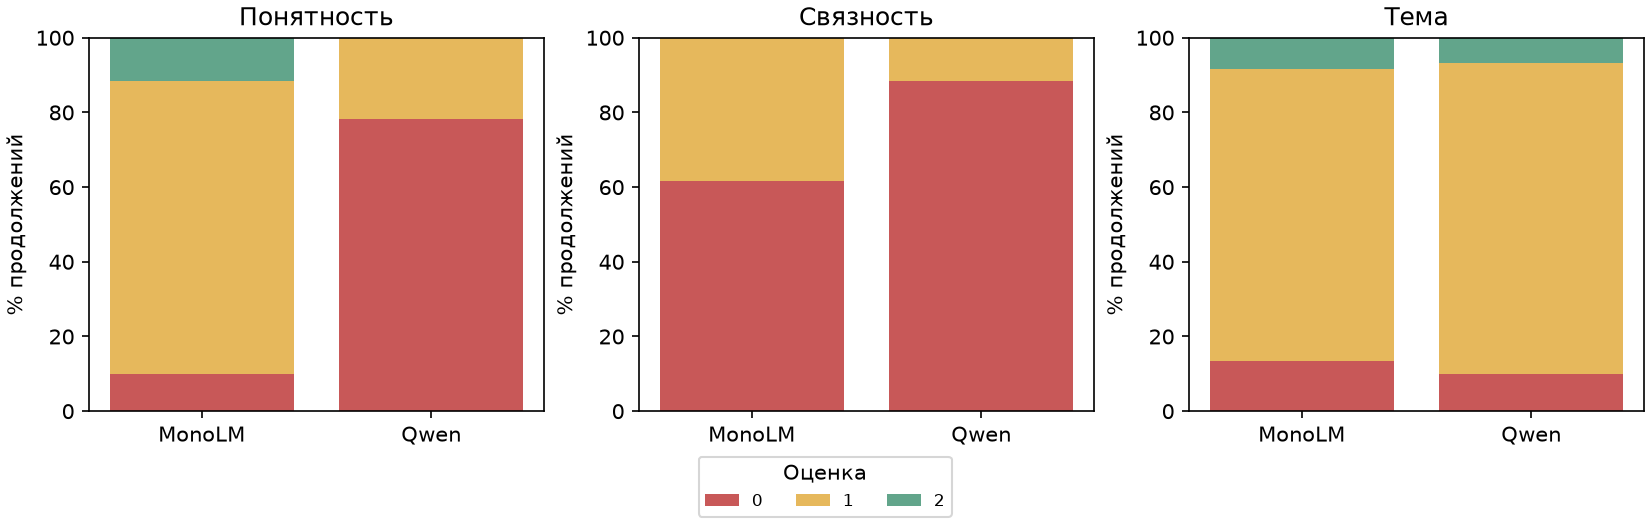

In [4]:
metrics = pd.DataFrame(report["metrics"])
display(metrics.assign(value=metrics.value*100, ci_low=metrics.ci_low*100, ci_high=metrics.ci_high*100).round(2))
difference = pd.DataFrame(report["paired_differences"])
display(difference.assign(value=difference.value*100, ci_low=difference.ci_low*100, ci_high=difference.ci_high*100).round(2))
display(Image(filename=str(A / "report/figures/outcomes.png")))
display(Image(filename=str(A / "report/figures/rubric.png")))

In [5]:
display(pd.DataFrame(report["automatic"]).round(3))
display(pd.DataFrame(report["defects"]))

,model,task,n,mean_words,mean_characters,empty_rate,repeat_5grams,mean_generation_seconds
0,monolm,continuation,60,75.250,475.8,0.033,0.057,3.327
1,monolm,qa,40,21.700,128.4,0.000,0.127,1.600
2,qwen,continuation,60,66.667,435.2,0.033,0.011,5.086
3,qwen,qa,40,6.325,43.2,0.000,0.000,1.476


,model,language,readability_0,coherence_0,relevance_0,degeneration,uncertain,qa_grades
0,monolm,"{'bulgarian': 58, 'unclear': 2}",6.0,37.0,8.0,10.0,0.0,NaN
1,monolm,NaN,NaN,NaN,NaN,NaN,NaN,"{'incorrect': 39, 'partial': 1}"
2,qwen,"{'bulgarian': 58, 'unclear': 2}",47.0,53.0,6.0,13.0,0.0,NaN
3,qwen,NaN,NaN,NaN,NaN,NaN,NaN,"{'incorrect': 15, 'correct': 19, 'partial': 6}"


## Заранее выбранные примеры

Первые три продолжения и первые формулировки первых трёх QA-заданий выбраны для иллюстраций до генерации. Для компактности ниже показаны первые 350 символов ответа. Полные ответы обеих моделей — в `report/examples.json` и `generations/*.jsonl`; все оценки — в `report/ratings.csv`.

In [6]:
for example in read("report/examples.json"):
    item = example["item"]
    title = item.get("question", item["prompt"])
    display(Markdown(f"**{item['id']} · {item['task']}**"))
    print(title)
    if item["task"] == "qa":
        print("Контекст:", item["context"])
        print("Эталон:", item["reference"])
    for model, answer in example["models"].items():
        r = answer["rating"]
        grade = r.get("qa_grade", {k:r.get(k) for k in ["language","readability","coherence","relevance","acceptable"]})
        print(model, grade)
        print(answer["response"][:350] + ("…" if len(answer["response"]) > 350 else ""))
        print("Причина:", r["reason"], "\n")

**c000 · continuation**

Какво причинява ограничаващ пулс?
Ограничаващ пулс е, когато човек усети, че сърцето му бие по-силно или по-енергично от обикновено.
Хората често се притесняват, че ограничителният пулс е признак на сърдечен проблем. Пристъпите на тревожност или паника обаче причиняват много случаи и ще се решат сами.
monolm {'language': 'bulgarian', 'readability': 1, 'coherence': 0, 'relevance': 1, 'acceptable': False}

Какво означава това при сърдечен проблем?
Отговор: При сърдечен проблем просто не се появяват признаци на сърдечен проблем. И двете неща са различни и всеки човек е различен.
По-конкретно, те са склонни да се притесняват, че не могат да използват и двете, защото не се нуждаят от кислород или други течности, които могат да им помогнат.
Те са по-скл…
Причина: Фразы читаются, но «не могат да използват и двете» не имеет ясного предмета, а «не се нуждаят от кислород» разрушает объяснение сердечного симптома. 

qwen {'language': 'bulgarian', 'readability': 0, 'coherence': 0, 'relevance': 1, 

**c001 · continuation**

МЕСТОПОЛОЖЕНИЕ и ОПИСАНИЕ НА ХОТЕЛА:
Хотел Белица е разположен на около 300 от плажа в Приморско.Град, известен със своето разнообразие и красота.
Освен, че е в близост до морето, хотелът предлага двойни стаи, озеленена площ и басейн с детски кът.
monolm {'language': 'bulgarian', 'readability': 2, 'coherence': 1, 'relevance': 1, 'acceptable': True}

Хотел Беласица е на около 300 метра от хотела, в близост до хотел Alpina на брега на Приморско.
Хотел Палм Спрингс е на около 250 метра от хотел Greenhill, докато хотел Residence е на около 200 метра от хотела.
Хотел Егер е на около 800 метра от хотела, в близост до хотел Eskdo и хотел Romeo Park.
Хотел Покана е на около 800 метра от хотела, в бли…
Причина: Понятен перечень расстояний до отелей, но смена точек отсчета «Greenhill», «хотела» ослабляет связь с описанием Белица. 

qwen {'language': 'bulgarian', 'readability': 0, 'coherence': 0, 'relevance': 0, 'acceptable': False}
 Столицата и пресег от международните и средно национални ъгли, 

**c002 · continuation**

...

Според описанието на Арманд Версаче какво се случва точно преди тълпата да започне да реагира на времето?
Контекст: След пет минути се вижда как започва да духа вятър, около минута по-късно вятърът достига 70 км/ч... тогава започва дъждът, но е толкова силен и капките са толкова едри, че удрят кожата ти като игла, след това от небето пада градушка, хората се паникьосват и крещят и се прегазват един друг. Арманд Версаче каза: „Загубих сестра си и приятелката й и по пътя ми имаше двама инвалиди в инвалидни колички, като хората просто ги прескачаха и ги бутаха“.
Эталон: Започва да вали градушка
monolm incorrect
В неделя сутринта се вижда как се появяват първите светлини.
Причина: «Първите светлини» не соответствует началу града перед паникой. 

qwen incorrect
Според описанието на Арманд Версаче, преди тълпата да започне да реагира на времето, се случва, че инвалидите са прескачани и бутнати, което
Причина: «Инвалидите са прескачани» описывает действия толпы, а не град перед ними. 



**q01v0 · qa**

Според откъса кое място в списъка с най-богатите американци заема Батен някога?
Контекст: Батен е класиран на 190-то място в списъка на 400-те най-богати американци за 2008 г. с богатство, оценявано на 2,3 милиарда долара. Той завършва Колежа по изкуства и науки в Университета на Вирджиния през 1950 г. и прави значителни дарения на институцията.
Эталон: 190-то
monolm incorrect
Батен е най-големият американски град.
Причина: «най-големият американски град» не сообщает место в рейтинге и ошибочно превращает человека в город. 

qwen correct
190-то.
Причина: «190-то» совпадает с указанным местом. 



**q02v0 · qa**

Какво помага на растенията в процеса на фотосинтеза?
Контекст: Растенията произвеждат кислород, който хората дишат, и приемат въглероден диоксид, който хората изпускат (т.е. издишват). Растенията произвеждат храната си от слънцето чрез фотосинтеза. Осигуряват и сянка. Строим къщите си от растения, както и правим дрехи от тях. Повечето ядливи храни са растения. Без растения животните не биха могли да оцелеят.
Эталон: Слънце
monolm incorrect
Растенията произвеждат кислород, който хората дишат, и приемат въглероден диоксид, който хората дишат, и приемат въглероден диоксид, който хората дишат, и приемат въглероден диоксид, който хората дишат, и приемат въглероден диоксид, който хората дишат, и приемат въглероден диоксид, който хората дишат, и приемат въглероден диоксид
Причина: Повтор «приемат въглероден диоксид» не отвечает о солнце, названном источником для фотосинтеза. 

qwen correct
Слънцето.
Причина: «Слънцето» точно соответствует указанному источнику для фотосинтеза. 



## Выводы и ограничения

**При мягком пороге на этих продолжениях MonoLM показала более высокую долю минимально приемлемого текста: 20/60 (33,3%) против 7/60 (11,7%).** Парная разность +21,7 п.п., 95% bootstrap-интервал [+6,6; +36,7]. Это результат для зафиксированных входов и параметров декодирования, не общее превосходство MonoLM. Минимально принятый ответ может быть шаблонным и лишь частично связным: пример с перечнем расстояний до отелей показывает, насколько мягок порог. **Со всеми оценками 2 — 0/60 у обеих моделей.**

**В ответах по контексту MonoLM пока не справилась:** 0/40 полностью правильных ответов и один частично правильный. У Qwen — 19/40 правильных, а 8/20 вопросов решены правильно в обеих формулировках. Нельзя утверждать, что наша модель надёжно отвечает на вопросы или понимает контекст на основании этого опыта.

Снижение validation loss нашей модели с **10,610 до 3,233** на одном фиксированном наборе из 262 144 токенов показывает улучшение предсказания отложенного текста. Бенчмарк дополняет это свидетельство проверкой генераций. Он не доказывает пользу фильтрации корпуса.

Все 18 контрольных оценок правильны. На повторной оценке согласие по минимальной пригодности — 23/24, по правильности QA — 16/16. Полное совпадение всех полей рубрики продолжений ниже: 16/24. Эти проверки не превращают модельных судей в носителей языка и не устраняют их общий возможный bias.

Qwen больше и обучалась на другом объёме данных. Поднабор QA намеренно простой, а продолжения отобраны по пригодности входов. По результатам нельзя оценить весь Belebele или исходный веб-корпус. Перплексии разных токенизаторов не сравниваются. Возможное попадание публичных заданий в pretrain Qwen не проверено. Использован один ответ на промпт; при других seed и настройках генерации результат может измениться.

In [7]:
for row in report["metrics"]:
    if row["model"] == "monolm":
        print(f"MonoLM · {row['block']} · {row['metric']}: {row['value']:.1%} (95% CI {row['ci_low']:.1%}–{row['ci_high']:.1%})")
for row in report["paired_differences"]:
    evidence = "интервал выше нуля" if row["ci_low"] > 0 else "интервал ниже нуля" if row["ci_high"] < 0 else "интервал включает ноль"
    print(f"Разность {row['metric']}: {100*row['value']:+.1f} п.п.; {evidence}.")
print("Минимальная пригодность не означает устойчивую связность, фактическую точность или надёжные ответы на вопросы.")
verification = read("verification.json")
assert verification["complete"] and verification["counts"] == report["counts"]
print("Артефактов с контрольными суммами:", len(verification["files"]))

MonoLM · continuation · minimal_acceptability: 33.3% (95% CI 21.7%–45.0%)
MonoLM · continuation · all_scores_2: 0.0% (95% CI 0.0%–0.0%)
MonoLM · qa · correct: 0.0% (95% CI 0.0%–0.0%)
MonoLM · qa · both_paraphrases_correct: 0.0% (95% CI 0.0%–0.0%)
Разность minimal_acceptability: +21.7 п.п.; интервал выше нуля.
Разность all_scores_2: +0.0 п.п.; интервал включает ноль.
Разность correct: -47.5 п.п.; интервал ниже нуля.
Разность both_paraphrases_correct: -40.0 п.п.; интервал ниже нуля.
Минимальная пригодность не означает устойчивую связность, фактическую точность или надёжные ответы на вопросы.
Артефактов с контрольными суммами: 93
